In [1]:
import os
from tqdm.auto import tqdm
import pandas as pd
from PIL import Image
import numpy as np
import torchvision
import torch
from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_recall_fscore_support, average_precision_score
from sklearn.preprocessing import label_binarize
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.models import resnet18, ResNet18_Weights
from torch.optim import AdamW
import matplotlib.pyplot as pltче
from pathlib import Path
from IPython.display import display

Matplotlib is building the font cache; this may take a moment.


In [4]:
gt_path = "../data/train.csv"
train_path = "../data/cassava_train"

## Посмотрим на данные
Есть дисбаланс классов

In [5]:
gt = pd.read_csv(gt_path)

In [6]:
gt.groupby("label").count()

,image_id
label,
0,1087
1,2189
2,2386
3,13158
4,2577


In [7]:
img = Image.open(f"{train_path}/6103.jpg").convert('RGB')

In [8]:
print(f"Shape = {np.array(img).shape}")

Shape = (256, 256, 3)


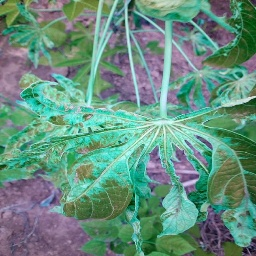

In [7]:
img

## Baseline: ResNet-18 (предобученный на ImageNet1k)
Основная метрика — macro F1. Дополнительно: precision, recall и macro PR-AUC, а также метрики по каждому классу.

Обучаем три независимые модели через StratifiedKFold(n_splits=3). В каждом фолде сохраняем лучший чекпойнт по validation macro F1 и историю обучения. Итоги показываем отдельно по фолдам и по объединённым out-of-fold (OOF) предсказаниям: каждое изображение предсказывает модель, для которой оно было в validation.

In [9]:
SEED, SIZE, BATCH, EPOCHS, LR = 18, 128, 128, 40, 1e-3
N_SPLITS = 3
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
CLASSES = ["CBB", "CBSD", "CGM", "CMD", "Healthy"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
np.random.seed(SEED)
CKPT_DIR = Path("checkpoints")
HISTORY_DIR = Path("training_history")
HISTORY_DIR.mkdir(parents=True, exist_ok=True)
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

In [10]:
df = pd.read_csv(gt_path)
from sklearn.model_selection import train_test_split

df, _ = train_test_split(
    df,
    train_size=4000,
    stratify=df["label"],
    random_state=SEED,
)
df = df.reset_index(drop=True)

print(f"Размер датасета: {len(df)}")
display(df["label"].value_counts().sort_index())

Размер датасета: 4000


label
0     203
1     409
2     446
3    2460
4     482
Name: count, dtype: int64

### Создаем датасет

In [10]:
class CassavaDS(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)
        self.tf = T.Compose([T.Resize((SIZE, SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, i):
        row = self.frame.iloc[i]
        x = self.tf(Image.open(Path(train_path) / row["image_id"]).convert("RGB"))
        return x, int(row["label"])

### Замораживаем 70% параметров модели, производим дообучение

In [11]:
def freeze_most(model, frozen_ratio=0.7):
    params = list(model.parameters())
    for i, p in enumerate(params):
        p.requires_grad = i >= int(frozen_ratio * len(params))

### Функции для метрик

In [12]:
def classification_metrics(y_true, y_pred, prob):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=range(len(CLASSES)), average="macro", zero_division=0
    )
    y_bin = label_binarize(y_true, classes=range(len(CLASSES)))
    return {
        "f1_macro": f1,
        "precision_macro": p,
        "recall_macro": r,
        "pr_auc_macro": average_precision_score(y_bin, prob, average="macro"),
    }


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    ys, probs = [], []
    total_loss, total_samples = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        total_loss += criterion(logits, y).item() * y.size(0)
        total_samples += y.size(0)
        ys.append(y.cpu().numpy())
        probs.append(logits.softmax(1).cpu().numpy())
    y_true = np.concatenate(ys)
    prob = np.vstack(probs)
    y_pred = prob.argmax(1)
    metrics = classification_metrics(y_true, y_pred, prob)
    metrics["loss"] = total_loss / total_samples
    return metrics, y_true, y_pred, prob


def per_class_table(y_true, y_pred):
    p, r, f1, n = precision_recall_fscore_support(
        y_true, y_pred, labels=range(len(CLASSES)), zero_division=0
    )
    return pd.DataFrame(
        {"precision": p, "recall": r, "f1": f1, "support": n}, index=CLASSES
    )

### Функция для обучения

In [13]:
def save_ckpt(path, state_dict, meta):
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"state_dict": state_dict, **meta}, path)


def train_split(tr, va, desc="train", ckpt_path=None):
    tr_ld = DataLoader(CassavaDS(tr), batch_size=BATCH, shuffle=True, pin_memory=DEVICE.type == "cuda")
    va_ld = DataLoader(CassavaDS(va), batch_size=BATCH, shuffle=False,  pin_memory=DEVICE.type == "cuda")
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    freeze_most(model, 0.7)
    model = model.to(DEVICE)
    opt = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
    crit = nn.CrossEntropyLoss()
    best_f1, best, best_epoch = -1.0, None, None
    history = []
    for ep in tqdm(range(EPOCHS), desc=desc):
        model.train()
        total_loss, total_samples = 0.0, 0
        train_true, train_pred = [], []
        for x, y in tqdm(tr_ld, desc=f"ep {ep + 1}/{EPOCHS}", leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits = model(x)
            loss = crit(logits, y)
            loss.backward()
            opt.step()
            total_loss += loss.item() * y.size(0)
            total_samples += y.size(0)
            train_true.extend(y.detach().cpu().tolist())
            train_pred.extend(logits.detach().argmax(1).cpu().tolist())
        _, _, train_f1, _ = precision_recall_fscore_support(
            train_true, train_pred, labels=range(len(CLASSES)), average="macro", zero_division=0
        )
        val_metrics, _, _, _ = evaluate(model, va_ld, crit)
        history.append({
            "epoch": ep + 1,
            "train_loss": total_loss / total_samples,
            "train_f1_macro": train_f1,
            **{f"val_{k}": v for k, v in val_metrics.items()},
        })
        f1 = val_metrics["f1_macro"]
        if f1 > best_f1:
            best_f1, best_epoch = f1, ep + 1
            best = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            if ckpt_path is not None:
                save_ckpt(ckpt_path, best, {"val_f1_macro": best_f1, "epoch": best_epoch})
        tqdm.write(
            f"{desc} ep {ep + 1}: train loss={history[-1]['train_loss']:.4f}, "
            f"val loss={val_metrics['loss']:.4f}, val F1={f1:.4f} (best={best_f1:.4f})"
        )
    model.load_state_dict(best)
    metrics, yt, yp, prob = evaluate(model, va_ld, crit)
    return {
        **metrics, "best_epoch": best_epoch,
        "per_class": per_class_table(yt, yp),
        "history": pd.DataFrame(history),
        "y_true": yt, "y_pred": yp, "prob": prob,
        "ckpt_path": str(ckpt_path) if ckpt_path is not None else None,
    }

### Обучение: StratifiedKFold, 3 фолда
В каждом фолде сохраняется доля классов. Модель и оптимизатор создаются заново; чекпойнты и история сохраняются отдельно для каждого фолда. Отдельного train/validation split нет.

In [ ]:
fold_results, histories, fold_rows = {}, {}, []
oof_prob = np.full((len(df), len(CLASSES)), np.nan, dtype=np.float32)
oof_fold = np.zeros(len(df), dtype=int)

for fold, (tr_i, va_i) in enumerate(skf.split(df, df["label"]), start=1):
    ckpt_path = CKPT_DIR / f"resnet18_fold_{fold}_best.pt"
    result = train_split(
        df.iloc[tr_i], df.iloc[va_i], desc=f"fold {fold}/{N_SPLITS}", ckpt_path=ckpt_path
    )
    result["val_indices"] = va_i
    fold_results[fold] = result
    histories[fold] = result["history"]
    histories[fold].to_csv(HISTORY_DIR / f"fold_{fold}_history.csv", index=False)
    oof_prob[va_i] = result["prob"]
    oof_fold[va_i] = fold
    fold_rows.append({
        "fold": fold, "best_epoch": result["best_epoch"],
        **{k: result[k] for k in ["loss", "f1_macro", "precision_macro", "recall_macro", "pr_auc_macro"]},
        "ckpt_path": result["ckpt_path"],
    })
    print(f"Фолд {fold}: метрики по классам на лучшей эпохе")
    display(result["per_class"])

fold_metrics = pd.DataFrame(fold_rows)
fold_metrics.to_csv(HISTORY_DIR / "fold_metrics.csv", index=False)
display(fold_metrics)
assert not np.isnan(oof_prob).any(), "Не все изображения получили OOF-предсказание"
oof_true = df["label"].to_numpy()
oof_pred = oof_prob.argmax(1)
oof_metrics = classification_metrics(oof_true, oof_pred, oof_prob)
print("Метрики по объединённым OOF-предсказаниям:")
display(pd.DataFrame([oof_metrics], index=["OOF"]))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 227MB/s]


fold 1/3:   0%|          | 0/40 [00:00<?, ?it/s]

ep 1/40:   0%|          | 0/27 [00:00<?, ?it/s]

fold 1/3 ep 1: train loss=1.0372, val loss=1.1131, val F1=0.3539 (best=0.3539)


ep 2/40:   0%|          | 0/27 [00:00<?, ?it/s]

... (226 outputs left out)

fold 3/3 ep 33: train loss=0.0152, val loss=1.7724, val F1=0.4356 (best=0.4679)


ep 34/40:   0%|          | 0/27 [00:00<?, ?it/s]

fold 3/3 ep 34: train loss=0.1079, val loss=1.9972, val F1=0.4232 (best=0.4679)


ep 35/40:   0%|          | 0/27 [00:00<?, ?it/s]

In [ ]:

display(per_class_table(oof_true, oof_pred))

,precision,recall,f1,support
CBB,0.422535,0.354331,0.385439,254
CBSD,0.452675,0.430528,0.441324,511
CGM,0.379939,0.224014,0.281849,558
CMD,0.815868,0.886179,0.849571,3075
Healthy,0.381329,0.400332,0.390600,602


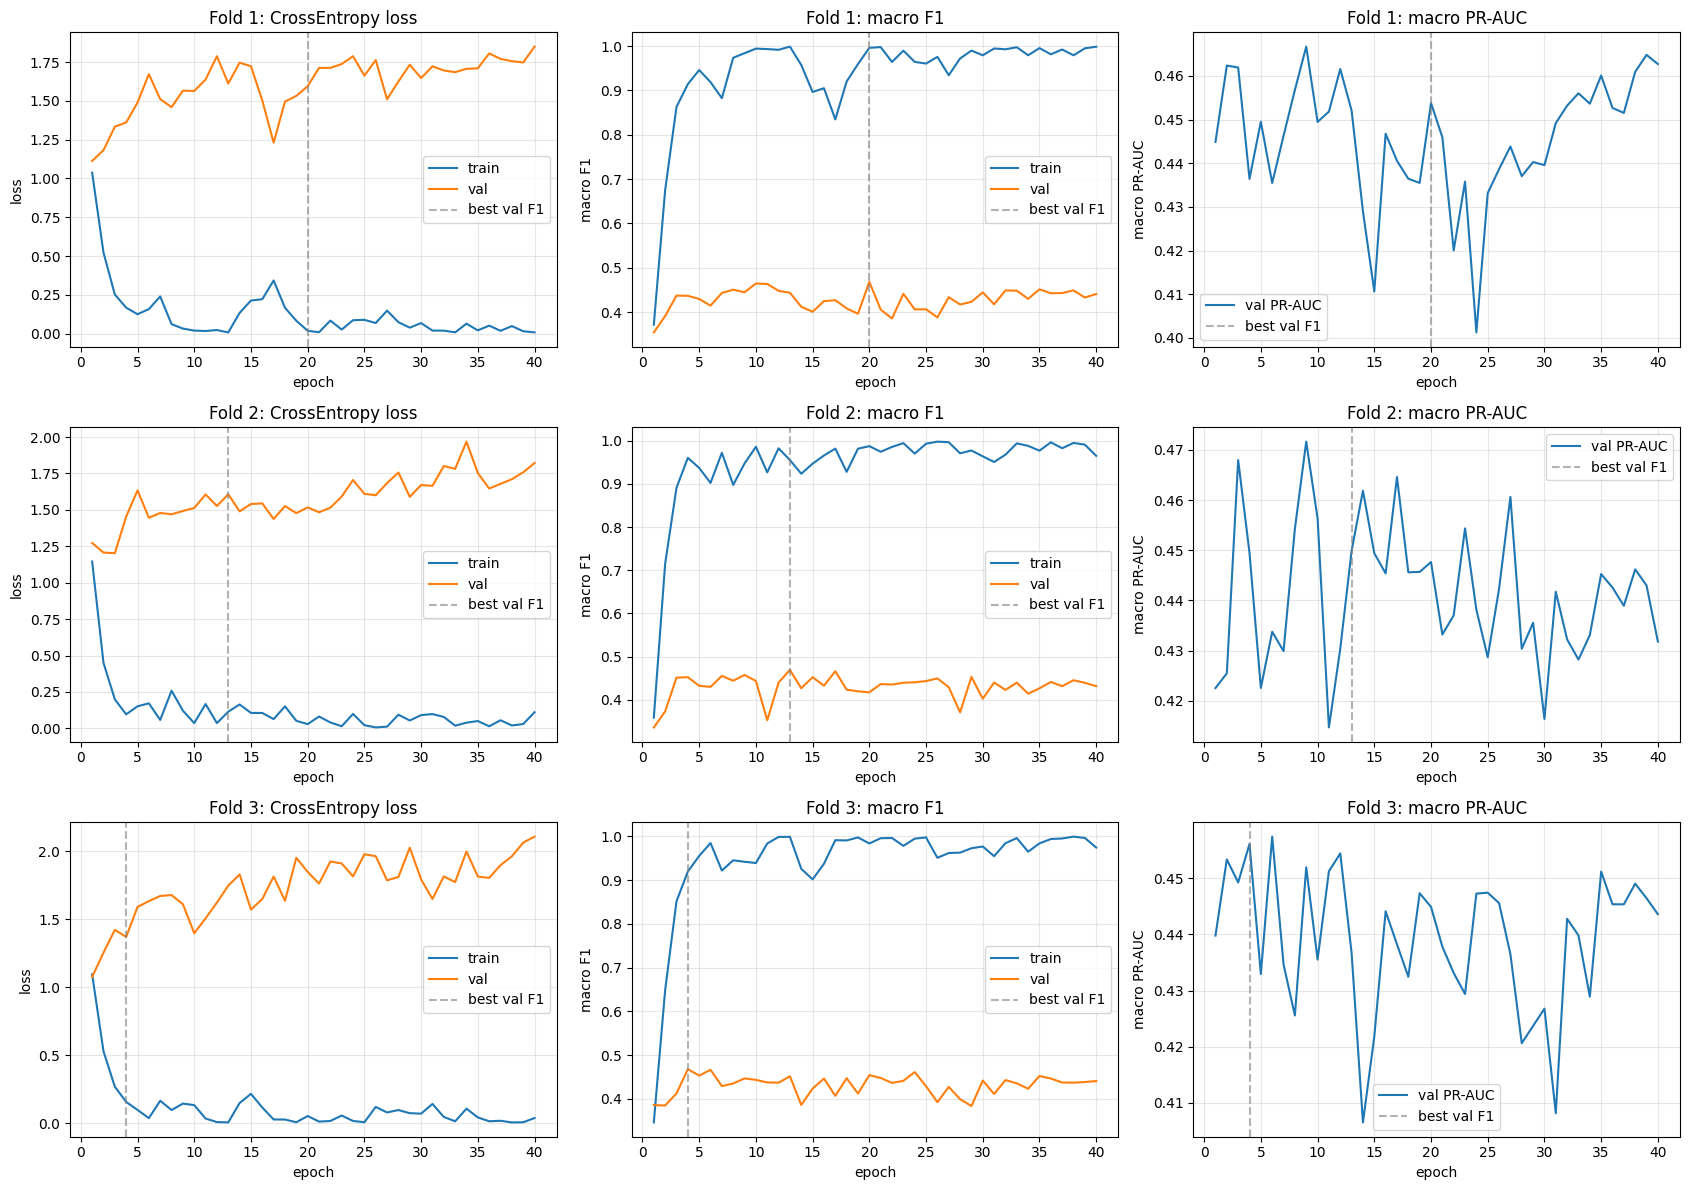

In [16]:
# История уже сохранена в CSV: графики можно построить повторно без обучения.
# Train-метрики собраны во время обновления весов; val — после каждой эпохи в model.eval().
def plot_training_curves(histories, fold_metrics=None):
    fig, axes = plt.subplots(len(histories), 3, figsize=(17, 4 * len(histories)), squeeze=False)
    for row, (fold, history) in enumerate(sorted(histories.items())):
        axes[row, 0].plot(history["epoch"], history["train_loss"], label="train")
        axes[row, 0].plot(history["epoch"], history["val_loss"], label="val")
        axes[row, 0].set_title(f"Fold {fold}: CrossEntropy loss")
        axes[row, 0].set_ylabel("loss")
        axes[row, 1].plot(history["epoch"], history["train_f1_macro"], label="train")
        axes[row, 1].plot(history["epoch"], history["val_f1_macro"], label="val")
        axes[row, 1].set_title(f"Fold {fold}: macro F1")
        axes[row, 1].set_ylabel("macro F1")
        axes[row, 2].plot(history["epoch"], history["val_pr_auc_macro"], label="val PR-AUC")
        axes[row, 2].set_title(f"Fold {fold}: macro PR-AUC")
        axes[row, 2].set_ylabel("macro PR-AUC")
        for ax in axes[row]:
            if fold_metrics is not None:
                best_epoch = fold_metrics.loc[fold_metrics["fold"] == fold, "best_epoch"].iloc[0]
                ax.axvline(best_epoch, color="gray", linestyle="--", alpha=0.6, label="best val F1")
            ax.set_xlabel("epoch")
            ax.grid(alpha=0.3)
            ax.legend()
    fig.tight_layout()
    return fig

histories_for_plot = {
    fold: pd.read_csv(HISTORY_DIR / f"fold_{fold}_history.csv")
    for fold in range(1, N_SPLITS + 1)
}
metrics_for_plot = pd.read_csv(HISTORY_DIR / "fold_metrics.csv")
fig = plot_training_curves(histories_for_plot, metrics_for_plot)
fig.savefig(HISTORY_DIR / "training_curves.png", dpi=160, bbox_inches="tight")
plt.show()

Ошибок Healthy → другое по OOF: 361


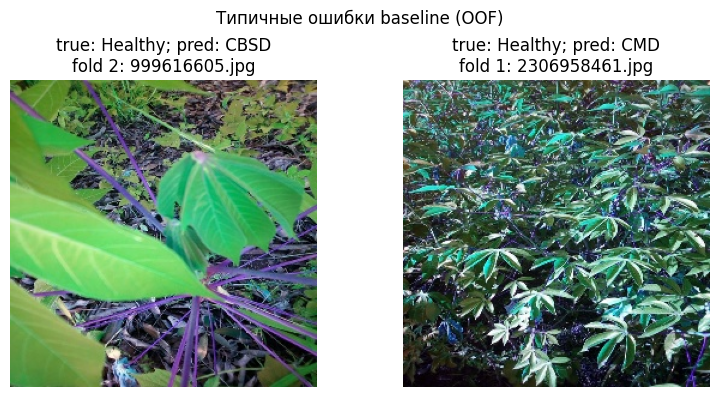

In [17]:
# Ошибки Healthy по OOF: изображение не входило в train предсказывающей модели.
HEALTHY = 4
idx = np.flatnonzero((oof_true == HEALTHY) & (oof_pred != HEALTHY))
print(f"Ошибок Healthy → другое по OOF: {len(idx)}")

if len(idx):
    count = min(2, len(idx))
    fig, axes = plt.subplots(1, count, figsize=(4 * count, 4), squeeze=False)
    for ax, i in zip(axes.ravel(), idx[:count]):
        row = df.iloc[i]
        with Image.open(Path(train_path) / row["image_id"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(
            f"true: Healthy; pred: {CLASSES[oof_pred[i]]}\n"
            f"fold {oof_fold[i]}: {row['image_id']}"
        )
        ax.axis("off")
    plt.suptitle("Типичные ошибки baseline (OOF)")
    plt.tight_layout()
    plt.show()
else:
    print("Ошибок Healthy → другое нет.")